# THỐNG KÊ MÁY TÍNH VÀ ỨNG DỤNG (ĐTTX)

**Khoa Công nghệ Thông tin - ĐH Khoa học Tự nhiên TP. HCM ([fit@hcmus](https://www.fit.hcmus.edu.vn/))**

*Giảng viên: Vũ Quốc Hoàng (vqhoang@fit.hcmus.edu.vn)*

# BÀI 5 - TRỰC QUAN HÓA DỮ LIỆU (Phần 1)

**Nội dung**

* [Giới thiệu](#gioi_thieu)
* [Giải phẫu một biểu đồ](#giai_phau)
* [Chọn biểu đồ theo câu hỏi](#chon_bieu_do)
  * [So sánh: biểu đồ thanh](#so_sanh)
  * [Xu hướng theo thời gian: biểu đồ đường](#xu_huong)
  * [Thành phần: biểu đồ quạt, thanh xếp chồng, miền xếp chồng](#thanh_phan)
  * [Phân bố: histogram](#phan_bo)
  * [Quan hệ: biểu đồ phân tán](#quan_he)
* [Nhiều biểu đồ trong một hình](#nhieu_bieu_do)
* [Lưu hình và đưa vào báo cáo](#luu_hinh)
* [Góc AI](#goc_ai)

**Tài liệu tham khảo**

* Chương 25 - 28 [Python Data Science Handbook (Jake VanderPlas)](https://www.amazon.com/Python-Data-Science-Handbook-Essential-dp-1098121228/dp/1098121228/)
* [Matplotlib: Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
* [From Data to Viz](https://www.data-to-viz.com/): chọn biểu đồ theo kiểu dữ liệu và câu hỏi
* Dữ liệu: [Our World in Data - Energy](https://github.com/owid/energy-data) (CC BY 4.0), [Gapminder](https://www.gapminder.org/data/) (CC BY 4.0)

## <a name="gioi_thieu"/>Giới thiệu

**Trực quan hóa dữ liệu** (data visualization) là công đoạn rất quan trọng trong phân tích dữ liệu với mục đích chính là **khám phá** (explore) và **mô tả** (describe) dữ liệu, rồi **trình bày** (communicate) kết quả cho người khác.

Bài 5 gồm 3 phần:

* Phần 1 (bài này): nền tảng với [**Matplotlib**](https://matplotlib.org/), thư viện trực quan hóa phổ biến nhất của Python, và cách **chọn biểu đồ theo câu hỏi**.
* Phần 2: biểu đồ thống kê với [**seaborn**](https://seaborn.pydata.org/) (xây dựng trên Matplotlib).
* Phần 3: biểu đồ tương tác với [**Plotly**](https://plotly.com/python/), bảng điều khiển (dashboard) với [**Streamlit**](https://streamlit.io/) và trực quan hóa cùng AI.

Nạp các thư viện với tên qui ước.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

**Vì sao phải vẽ?** Xét 4 bộ dữ liệu nhỏ sau ([Anscombe, 1973](https://en.wikipedia.org/wiki/Anscombe%27s_quartet)), mỗi bộ có 11 cặp giá trị $(x, y)$.

In [2]:
x123 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "I":   (x123, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  (x123, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": (x123, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

pd.DataFrame({ten: {"TB của x": np.mean(x), "TB của y": np.mean(y),
                    "Phương sai x": np.var(x, ddof=1), "Phương sai y": np.var(y, ddof=1),
                    "Hệ số tương quan": np.corrcoef(x, y)[0, 1]}
              for ten, (x, y) in anscombe.items()}).round(2)

,I,II,III,IV
TB của x,9.00,9.00,9.00,9.00
TB của y,7.50,7.50,7.50,7.50
Phương sai x,11.00,11.00,11.00,11.00
Phương sai y,4.13,4.13,4.12,4.12
Hệ số tương quan,0.82,0.82,0.82,0.82


Các con số tóm tắt gần như trùng nhau, kể cả đường hồi quy (xấp xỉ $y = 3 + 0.5x$). Nhưng hãy vẽ ra.

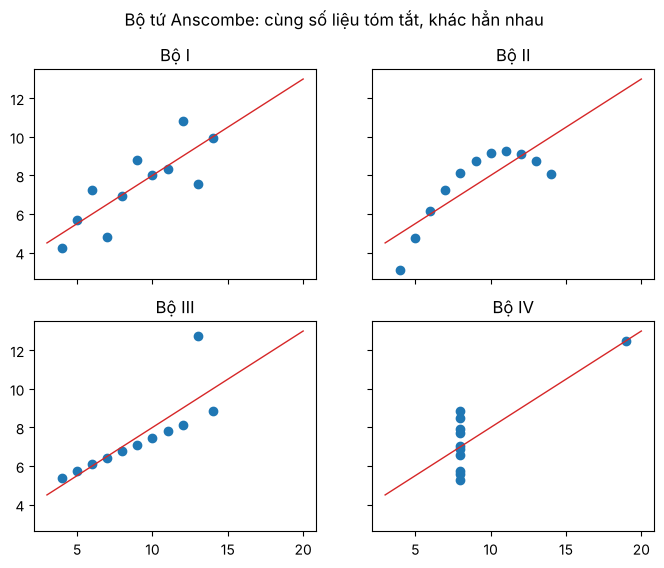

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True)
x_duong = np.array([3, 20])
for ax, (ten, (x, y)) in zip(axs.flat, anscombe.items()):
    ax.scatter(x, y)
    ax.plot(x_duong, 3 + 0.5 * x_duong, color="tab:red", linewidth=1)
    ax.set_title(f"Bộ {ten}")
fig.suptitle("Bộ tứ Anscombe: cùng số liệu tóm tắt, khác hẳn nhau")
plt.show()

Bốn bộ dữ liệu hoàn toàn khác nhau: bộ I gần tuyến tính; bộ II là một đường cong; bộ III tuyến tính nhưng có một điểm ngoại lai; bộ IV gần như không có quan hệ, chỉ một điểm "kéo" cả đường hồi quy.

Chỉ nhìn các con số tóm tắt (do người hay do AI đưa ra) có thể bỏ sót những điều mà biểu đồ cho thấy ngay.

## <a name="giai_phau"/>Giải phẫu một biểu đồ

Matplotlib có thể được dùng theo 2 cách.

Cách thứ nhất là **dựa trên trạng thái** (state-based) tương tự như MATLAB: các hàm trong `plt` vẽ lên biểu đồ "hiện tại".

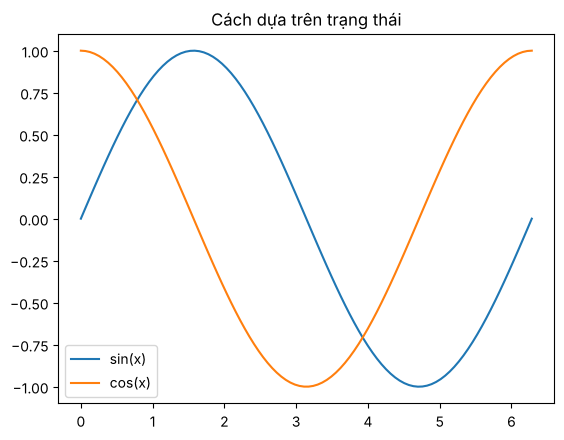

In [4]:
x = np.linspace(0, 2*np.pi, 100)

plt.plot(x, np.sin(x), label="sin(x)")
plt.plot(x, np.cos(x), label="cos(x)")
plt.title("Cách dựa trên trạng thái")
plt.legend()
plt.show()

Cách thứ hai là **hướng đối tượng** (object-oriented): tạo hình (`fig`) và các biểu đồ (`ax`) bằng `plt.subplots`, rồi gọi phương thức trên từng biểu đồ.

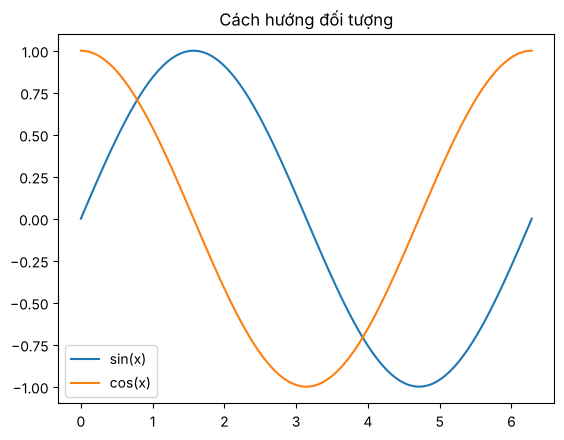

In [5]:
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), label="cos(x)")
ax.set_title("Cách hướng đối tượng")
ax.legend()
plt.show()

Cách hướng đối tượng rõ ràng hơn khi một hình có nhiều biểu đồ và khi viết hàm vẽ để dùng lại; tài liệu Matplotlib khuyên dùng cách này cho các hình phức tạp. **Từ bài này, ta dùng cách hướng đối tượng.**

Các thành phần chính của một biểu đồ:

| Thành phần | Ý nghĩa | Phương thức |
|---|---|---|
| Hình (`Figure`) | toàn bộ khung hình, có thể chứa nhiều biểu đồ | `plt.subplots`, `fig.suptitle`, `fig.savefig` |
| Biểu đồ (`Axes`) | một hệ trục với dữ liệu được vẽ | `ax.plot`, `ax.bar`, `ax.scatter`, `ax.hist`, ... |
| Tiêu đề | biểu đồ nói về điều gì | `ax.set_title` |
| Nhãn trục | đại lượng và **đơn vị** | `ax.set_xlabel`, `ax.set_ylabel` |
| Giới hạn, vạch chia | phạm vi và các mốc trên trục | `ax.set_xlim`, `ax.set_ylim`, `ax.set_xticks` |
| Chú thích | phân biệt các nhóm dữ liệu | `ax.legend` |
| Lưới | giúp đọc giá trị | `ax.grid` |
| Ghi chú | nhấn mạnh một điểm | `ax.annotate`, `ax.text` |

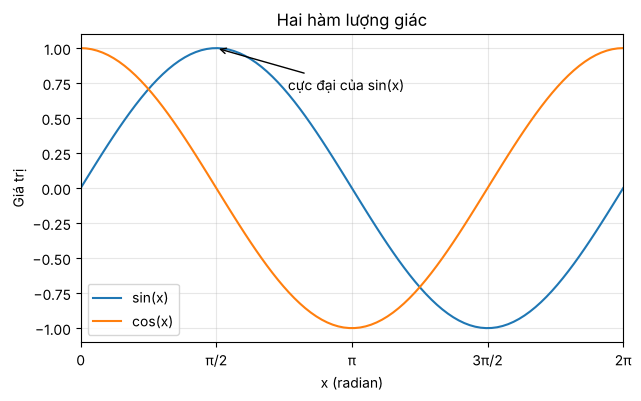

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(x), label="sin(x)")
ax.plot(x, np.cos(x), label="cos(x)")

ax.set_title("Hai hàm lượng giác")
ax.set_xlabel("x (radian)")
ax.set_ylabel("Giá trị")
ax.set_xlim(0, 2*np.pi)
ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi], ["0", "π/2", "π", "3π/2", "2π"])
ax.grid(alpha=0.3)
ax.annotate("cực đại của sin(x)", xy=(np.pi/2, 1), xytext=(2.4, 0.7),
            arrowprops=dict(arrowstyle="->"))
ax.legend(loc="lower left")

plt.show()

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Theo cách hướng đối tượng, vẽ đồ thị các hàm số sau trên khoảng $[-2, 2]$
  - $y = x$
  - $y = x^2$
  - $y = |x|$

trên cùng một biểu đồ, rồi trên 3 biểu đồ riêng trong cùng một hình. Thử các style khác nhau mà Matplotlib hỗ trợ (`plt.style.available`).

In [7]:
# TODO:

## <a name="chon_bieu_do"/>Chọn biểu đồ theo câu hỏi

Trước khi vẽ, hãy hỏi: **biểu đồ này cần trả lời câu hỏi gì?** Câu hỏi quyết định loại biểu đồ.

| Câu hỏi | Ví dụ | Biểu đồ phù hợp |
|---|---|---|
| **So sánh** các nhóm | Nước nào sản xuất nhiều điện nhất? | Thanh (đứng hoặc ngang) |
| **Xu hướng** theo thời gian | Sản lượng điện thay đổi thế nào qua các năm? | Đường |
| **Thành phần** (bộ phận - toàn thể) | Điện được sản xuất từ những nguồn nào? | Thanh xếp chồng, miền xếp chồng; quạt (khi ít phần) |
| **Phân bố** của một biến | Tuổi thọ các nước tập trung ở khoảng nào? | Histogram (Phần 2: boxplot, mật độ) |
| **Quan hệ** giữa hai biến | Nước giàu hơn có sống lâu hơn không? | Phân tán |

Một biểu đồ tốt trả lời **một** câu hỏi rõ ràng; tiêu đề có thể chính là câu trả lời.

Dữ liệu `DienNang_DongNamA.csv`: điện năng của 10 nước Đông Nam Á từ năm 2000 đến 2025, trích từ [Our World in Data](https://github.com/owid/energy-data) (dựa trên số liệu của Ember và Energy Institute; giấy phép CC BY 4.0). Brunei, Indonesia, Lào, Myanmar chỉ có số liệu đến năm 2024; số liệu năm gần nhất có thể là số liệu sơ bộ.

| Cột | Ý nghĩa |
|---|---|
| `quoc_gia`, `nam` | quốc gia, năm |
| `dan_so` | dân số (người) |
| `san_luong` | sản lượng điện sản xuất (TWh, 1 TWh = 1 tỷ kWh) |
| `binh_quan` | sản lượng điện bình quân đầu người (kWh/người) |
| `than`, `khi`, `dau`, `thuy_dien`, `mat_troi`, `gio`, `sinh_khoi`, `khac` | sản lượng theo nguồn (TWh); tổng các nguồn bằng `san_luong` |

In [8]:
dien = pd.read_csv("DienNang_DongNamA.csv")
dien

,quoc_gia,nam,dan_so,san_luong,binh_quan,than,khi,dau,thuy_dien,mat_troi,gio,sinh_khoi,khac
0,Brunei,2000,326429,2.54,7781.2,0.00,2.52,0.02,0.00,0.00,0.00,0.00,0.0
1,Brunei,2001,333353,2.58,7739.5,0.00,2.56,0.02,0.00,0.00,0.00,0.00,0.0
2,Brunei,2002,340108,2.71,7968.1,0.00,2.68,0.03,0.00,0.00,0.00,0.00,0.0
3,Brunei,2003,346650,3.20,9231.2,0.00,3.17,0.03,0.00,0.00,0.00,0.00,0.0
4,Brunei,2004,352921,3.26,9237.2,0.00,3.23,0.03,0.00,0.00,0.00,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,Việt Nam,2021,98935101,253.61,2563.4,118.03,26.31,0.79,78.67,26.15,3.34,0.32,0.0
252,Việt Nam,2022,99680656,265.11,2659.6,104.04,29.22,0.72,95.91,25.75,9.09,0.38,0.0
253,Việt Nam,2023,100352189,276.59,2756.2,129.76,26.36,1.70,80.62,25.69,11.59,0.87,0.0
254,Việt Nam,2024,100987685,303.58,3006.1,152.77,21.83,0.62,88.72,25.86,12.75,1.03,0.0


Đặt sẵn thứ tự, tên và **màu cố định** cho từng nguồn điện để mọi biểu đồ trong bài dùng thống nhất (màu đi theo đối tượng: thủy điện luôn màu xanh dương, mặt trời luôn màu vàng, ...).

In [9]:
NGUON = ["than", "khi", "dau", "thuy_dien", "mat_troi", "gio", "sinh_khoi", "khac"]
TEN_NGUON = {"than": "Than", "khi": "Khí", "dau": "Dầu", "thuy_dien": "Thủy điện",
             "mat_troi": "Mặt trời", "gio": "Gió", "sinh_khoi": "Sinh khối", "khac": "Khác"}
MAU_NGUON = {"than": "#5a5a5a", "khi": "#f28e2b", "dau": "#8c564b", "thuy_dien": "#1f77b4",
             "mat_troi": "#c99700", "gio": "#17becf", "sinh_khoi": "#2ca02c", "khac": "#a6a6a6"}

### <a name="so_sanh"/>So sánh: biểu đồ thanh

So sánh sản lượng điện các nước năm 2024 bằng biểu đồ thanh ngang ([`barh`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.barh.html)): thuận tiện khi tên nhóm dài. Nên **sắp xếp** các thanh và **tô nổi** nhóm cần chú ý.

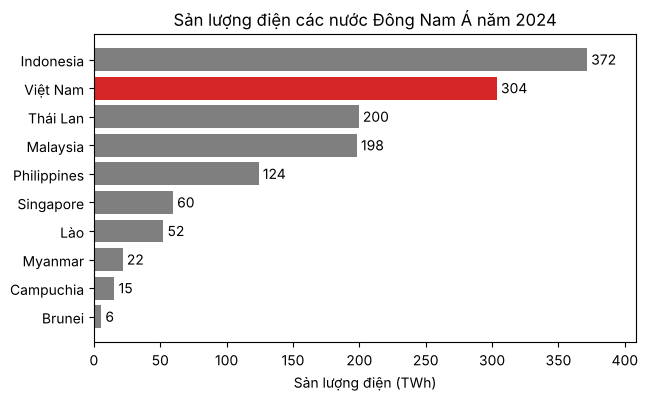

In [10]:
nam_2024 = dien[dien.nam == 2024].sort_values("san_luong")
mau = ["tab:red" if qg == "Việt Nam" else "tab:gray" for qg in nam_2024.quoc_gia]

fig, ax = plt.subplots(figsize=(7, 4))
thanh = ax.barh(nam_2024.quoc_gia, nam_2024.san_luong, color=mau)
ax.bar_label(thanh, fmt="%.0f", padding=3)        # ghi giá trị ở cuối mỗi thanh
ax.margins(x=0.1)
ax.set_title("Sản lượng điện các nước Đông Nam Á năm 2024")
ax.set_xlabel("Sản lượng điện (TWh)")
plt.show()

**Biểu đồ thanh gom nhóm** (grouped bar chart): so sánh sản lượng năm 2015 và 2024 của từng nước. Hai thanh của mỗi nhóm được đặt lệch lên, xuống nửa độ rộng thanh so với vị trí của nhóm.

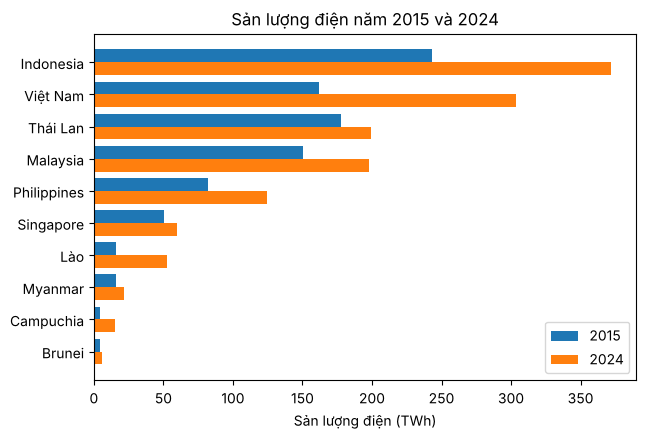

In [11]:
bang = (dien[dien.nam.isin([2015, 2024])]
        .pivot(index="quoc_gia", columns="nam", values="san_luong")
        .sort_values(2024))

y = np.arange(len(bang))
h = 0.4
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(y + h/2, bang[2015], height=h, label="2015")
ax.barh(y - h/2, bang[2024], height=h, label="2024")
ax.set_yticks(y, bang.index)
ax.set_title("Sản lượng điện năm 2015 và 2024")
ax.set_xlabel("Sản lượng điện (TWh)")
ax.legend()
plt.show()

Hoặc vẽ nhanh bằng pandas (pandas dùng Matplotlib và trả về `ax` để chỉnh tiếp).

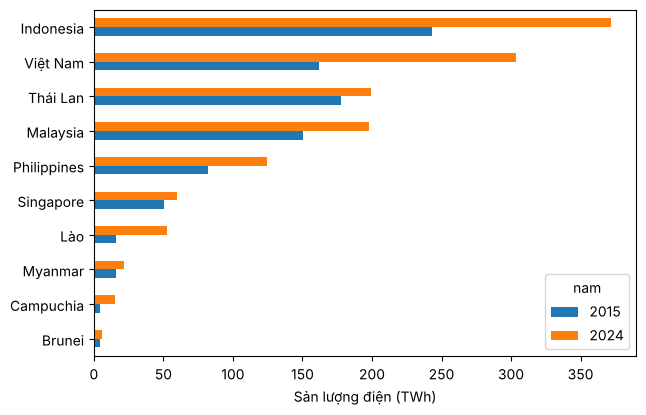

In [12]:
ax = bang.plot.barh(figsize=(7, 4.5))
ax.set_xlabel("Sản lượng điện (TWh)")
ax.set_ylabel("")
plt.show()

Việt Nam đứng thứ 2 về tổng sản lượng. Nhưng so sánh **tổng** hay **bình quân đầu người** là hai câu hỏi khác nhau.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ biểu đồ thanh ngang cho sản lượng điện bình quân đầu người (`binh_quan`) năm 2024, sắp xếp và tô nổi Việt Nam. So sánh thứ hạng với biểu đồ sản lượng ở trên. Vì sao Lào có bình quân rất cao? *(Gợi ý: `binh_quan` tính theo điện **sản xuất**, không phải điện tiêu dùng.)*

In [13]:
# TODO:

### <a name="xu_huong"/>Xu hướng theo thời gian: biểu đồ đường

**Biểu đồ đường** (line chart) thể hiện sự thay đổi theo thời gian: trục hoành là thời gian, các điểm được nối theo thứ tự.

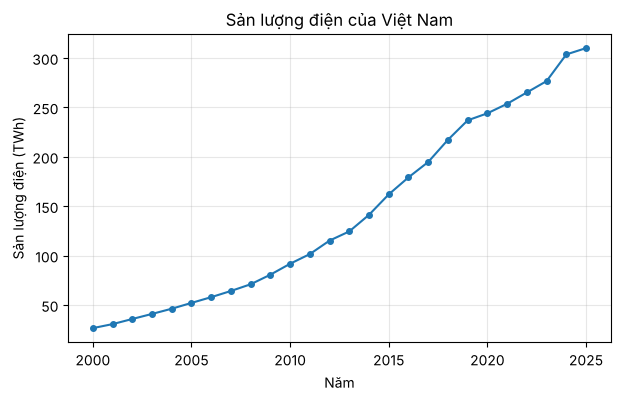

In [14]:
vn = dien[dien.quoc_gia == "Việt Nam"].set_index("nam")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vn.index, vn.san_luong, marker="o", markersize=4)
ax.set_title("Sản lượng điện của Việt Nam")
ax.set_xlabel("Năm")
ax.set_ylabel("Sản lượng điện (TWh)")
ax.grid(alpha=0.3)
plt.show()

Nhiều đường trên cùng một biểu đồ giúp so sánh xu hướng giữa các nhóm.

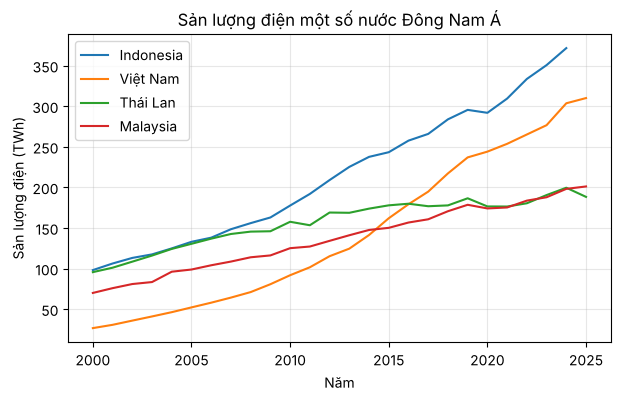

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for qg in ["Indonesia", "Việt Nam", "Thái Lan", "Malaysia"]:
    d = dien[dien.quoc_gia == qg]
    ax.plot(d.nam, d.san_luong, label=qg)
ax.set_title("Sản lượng điện một số nước Đông Nam Á")
ax.set_xlabel("Năm")
ax.set_ylabel("Sản lượng điện (TWh)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Trục tung có cần bắt đầu từ 0?** Xét dữ liệu lợi nhuận (triệu USD) của một công ty trong 6 tháng.

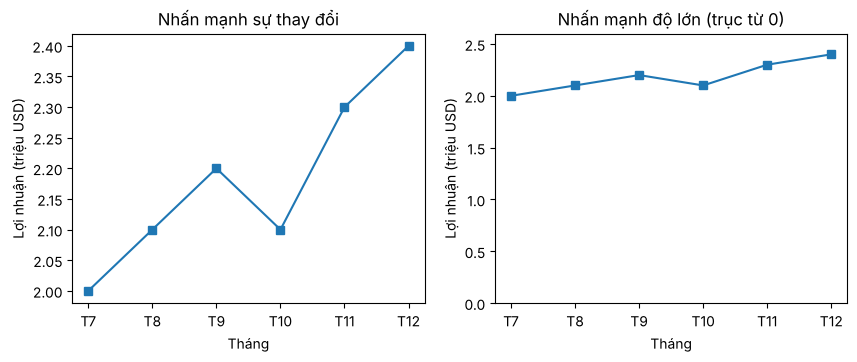

In [16]:
thang = ["T7", "T8", "T9", "T10", "T11", "T12"]
loi_nhuan = [2.0, 2.1, 2.2, 2.1, 2.3, 2.4]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(thang, loi_nhuan, marker="s")
ax1.set_title("Nhấn mạnh sự thay đổi")
ax2.plot(thang, loi_nhuan, marker="s")
ax2.set_ylim(0, 2.6)
ax2.set_title("Nhấn mạnh độ lớn (trục từ 0)")
for ax in (ax1, ax2):
    ax.set_xlabel("Tháng")
    ax.set_ylabel("Lợi nhuận (triệu USD)")
plt.show()

Cùng dữ liệu nhưng ấn tượng rất khác: bên trái lợi nhuận như "tăng vọt", bên phải gần như ổn định. Với biểu đồ đường, chọn theo câu hỏi (thay đổi hay độ lớn) và nói rõ trong tiêu đề. Với **biểu đồ thanh, trục luôn phải bắt đầu từ 0** vì độ dài thanh biểu diễn giá trị (xem thêm [Misleading graph](https://en.wikipedia.org/wiki/Misleading_graph) và Phần 3).

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ sản lượng điện mặt trời và điện gió của Việt Nam từ 2015 đến nay trên cùng một biểu đồ, dùng màu trong `MAU_NGUON`. Nhận xét giai đoạn 2019 - 2021.

In [17]:
# TODO:

### <a name="thanh_phan"/>Thành phần: biểu đồ quạt, thanh xếp chồng, miền xếp chồng

Câu hỏi: điện của Việt Nam năm 2024 được sản xuất từ những nguồn nào, mỗi nguồn chiếm bao nhiêu?

In [18]:
co_cau = vn.loc[2024, NGUON].astype(float)
ti_le = co_cau / co_cau.sum()
pd.DataFrame({"TWh": co_cau, "Tỉ lệ (%)": (100 * ti_le).round(1)}).rename(index=TEN_NGUON)

,TWh,Tỉ lệ (%)
Than,152.77,50.3
Khí,21.83,7.2
Dầu,0.62,0.2
Thủy điện,88.72,29.2
Mặt trời,25.86,8.5
Gió,12.75,4.2
Sinh khối,1.03,0.3
Khác,0.00,0.0


**Biểu đồ quạt** ([`pie`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.pie.html)) chỉ dễ đọc khi có ít phần (khoảng 5 phần trở xuống) và tổng các phần có ý nghĩa. Ở đây gộp các nguồn nhỏ (dưới 5%) vào "Khác" và xếp các phần từ lớn đến nhỏ.

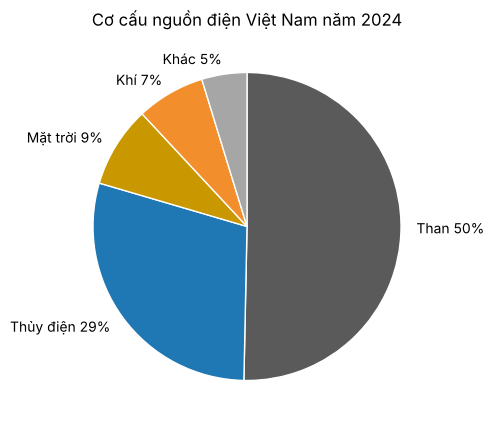

In [19]:
lon = ti_le[ti_le >= 0.05].sort_values(ascending=False)
gop = pd.concat([lon, pd.Series({"khac": ti_le[ti_le < 0.05].sum()})])

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(gop, labels=[f"{TEN_NGUON[k]} {v:.0%}" for k, v in gop.items()],
       colors=[MAU_NGUON[k] for k in gop.index],
       startangle=90, counterclock=False, wedgeprops=dict(edgecolor="white"))
ax.set_title("Cơ cấu nguồn điện Việt Nam năm 2024")
plt.show()

**Biểu đồ thanh xếp chồng** (stacked bar chart) cho thấy thành phần của nhiều nhóm cùng lúc. Vẽ theo tỉ lệ (%) để so sánh cơ cấu giữa các năm; mỗi đoạn bắt đầu tại điểm kết thúc của đoạn trước (tham số `left`).

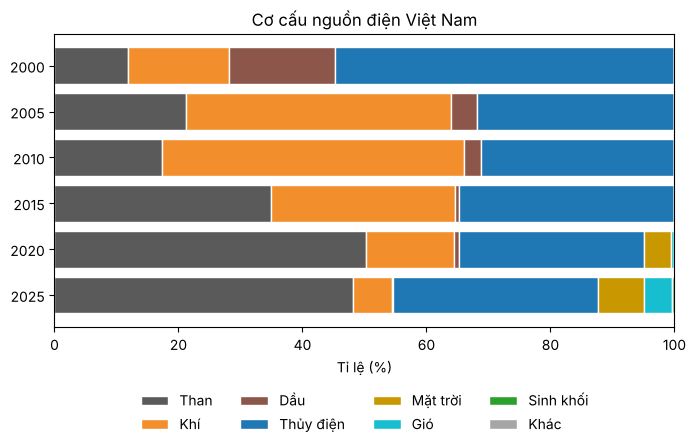

In [20]:
nam_chon = [2000, 2005, 2010, 2015, 2020, 2025]
san_luong_chon = vn.loc[nam_chon, NGUON]
ti_le_nam = 100 * san_luong_chon.div(san_luong_chon.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
trai = np.zeros(len(nam_chon))
for ng in NGUON:
    ax.barh([str(n) for n in nam_chon], ti_le_nam[ng], left=trai,
            color=MAU_NGUON[ng], label=TEN_NGUON[ng], edgecolor="white")
    trai = trai + ti_le_nam[ng].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Tỉ lệ (%)")
ax.set_title("Cơ cấu nguồn điện Việt Nam")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.show()

**Biểu đồ miền xếp chồng** (stacked area chart, [`stackplot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.stackplot.html)) cho thấy cả tổng lẫn thành phần thay đổi liên tục theo thời gian.

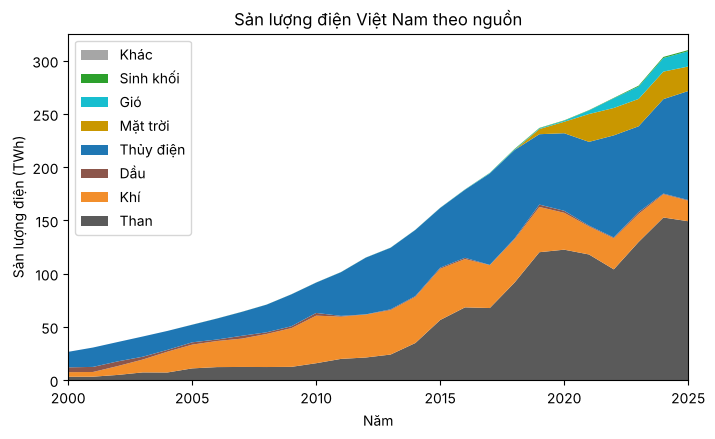

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.stackplot(vn.index, [vn[ng] for ng in NGUON],
             labels=[TEN_NGUON[ng] for ng in NGUON], colors=[MAU_NGUON[ng] for ng in NGUON])
ax.set_xlim(vn.index.min(), vn.index.max())
ax.set_title("Sản lượng điện Việt Nam theo nguồn")
ax.set_xlabel("Năm")
ax.set_ylabel("Sản lượng điện (TWh)")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left")   # thứ tự chú thích khớp thứ tự các miền
plt.show()

Nhận xét: tổng sản lượng tăng gần 12 lần trong 25 năm (dân số chỉ tăng khoảng 1,3 lần). Thủy điện chiếm hơn một nửa năm 2000; nguồn lớn nhất lần lượt là thủy điện (2000 - 2003), khí (2004 - 2010), thủy điện (2011 - 2014); từ 2018 than là nguồn lớn nhất (khoảng một nửa năm 2024); điện mặt trời tăng vọt trong giai đoạn 2019 - 2021.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ biểu đồ miền xếp chồng **theo tỉ lệ (%)** cho cơ cấu nguồn điện của Thái Lan. So sánh với Việt Nam.

In [22]:
# TODO:

### <a name="phan_bo"/>Phân bố: histogram

**Histogram** cho thấy phân bố của một đại lượng trên miền giá trị: tần số (hay tần suất, mật độ) các mẫu dữ liệu trên các khoảng giá trị.

Dữ liệu `gapminder.csv`: tuổi thọ trung bình, dân số và GDP bình quân đầu người của 142 quốc gia từ 1952 đến 2007, 5 năm một lần ([Gapminder](https://www.gapminder.org/data/), CC BY 4.0; bản đi kèm thư viện Plotly). Tên quốc gia giữ tiếng Anh.

| Cột | Ý nghĩa |
|---|---|
| `quoc_gia`, `chau_luc`, `nam` | quốc gia, châu lục, năm |
| `tuoi_tho` | tuổi thọ trung bình (năm) |
| `dan_so` | dân số (người) |
| `gdp_binh_quan` | GDP bình quân đầu người (USD, đã điều chỉnh lạm phát và sức mua) |
| `ma_iso` | mã quốc gia ISO 3 ký tự (dùng để vẽ bản đồ ở Phần 3) |

In [23]:
gap = pd.read_csv("gapminder.csv")
g2007 = gap[gap.nam == 2007]
g2007.describe()

,nam,tuoi_tho,dan_so,gdp_binh_quan
count,142.0,142.000000,1.420000e+02,142.000000
mean,2007.0,67.007394,4.402122e+07,11680.076056
std,0.0,12.072808,1.476214e+08,12859.936254
min,2007.0,39.610000,1.995790e+05,277.600000
25%,2007.0,57.162500,4.508034e+06,1624.825000
50%,2007.0,71.935000,1.051753e+07,6124.400000
75%,2007.0,76.410000,3.121004e+07,18008.800000
max,2007.0,82.600000,1.318683e+09,49357.200000


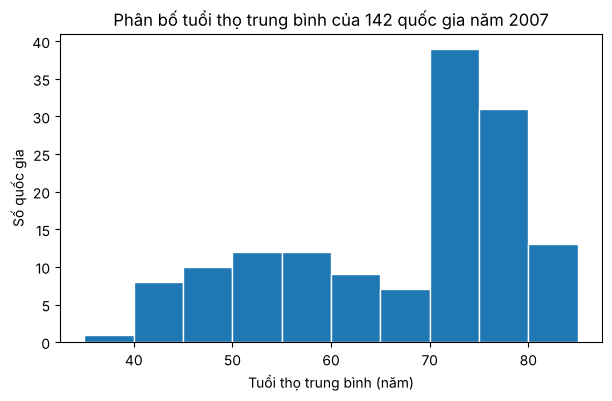

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(g2007.tuoi_tho, bins=np.arange(35, 90, 5), edgecolor="white")
ax.set_title("Phân bố tuổi thọ trung bình của 142 quốc gia năm 2007")
ax.set_xlabel("Tuổi thọ trung bình (năm)")
ax.set_ylabel("Số quốc gia")
plt.show()

Phân bố lệch trái: nhiều nước có tuổi thọ 70 - 80, nhưng có một nhóm khá lớn dưới 55 (hầu hết ở châu Phi; Phần 2 sẽ tách theo châu lục).

Với **các khoảng chia không đều**, cần vẽ histogram theo **mật độ** (density): diện tích mỗi thanh tỉ lệ với **tần suất** (tỉ lệ mẫu rơi vào khoảng), tức là chiều cao bằng tần suất chia độ dài khoảng.

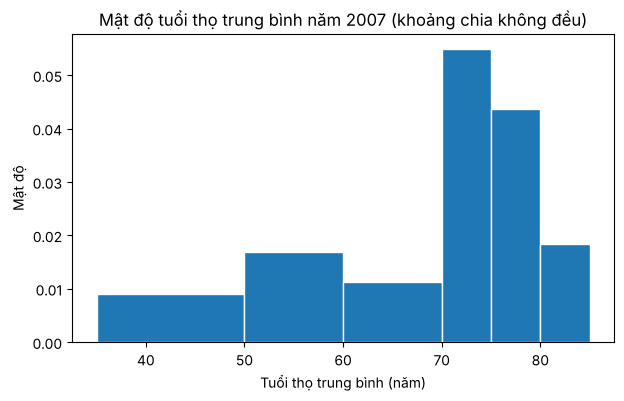

In [25]:
khoang = [35, 50, 60, 70, 75, 80, 85]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(g2007.tuoi_tho, bins=khoang, density=True, edgecolor="white")
ax.set_title("Mật độ tuổi thọ trung bình năm 2007 (khoảng chia không đều)")
ax.set_xlabel("Tuổi thọ trung bình (năm)")
ax.set_ylabel("Mật độ")
plt.show()

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ histogram cho GDP bình quân đầu người năm 2007. Phân bố có dạng gì? Vẽ lại với các khoảng chia đều theo **thang log** (gợi ý: `np.logspace` và `ax.set_xscale("log")`) và nhận xét.

In [26]:
# TODO:

### <a name="quan_he"/>Quan hệ: biểu đồ phân tán

**Biểu đồ phân tán** (scatter plot) mô tả quan hệ giữa 2 đại lượng số. Hàm [`scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html) còn cho phép kích thước, màu của mỗi điểm phụ thuộc dữ liệu.

Biểu đồ sau mô tả quan hệ giữa GDP bình quân và tuổi thọ năm 2007: màu theo châu lục, kích thước theo dân số. Trục hoành dùng **thang log** vì GDP bình quân trải từ vài trăm đến vài chục nghìn USD.

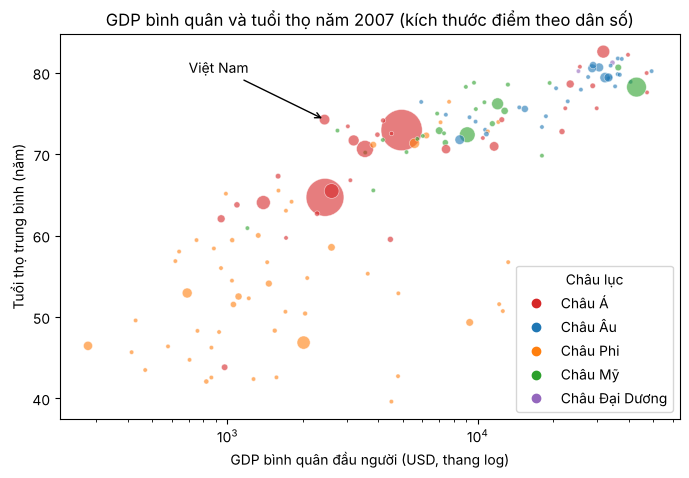

In [27]:
from matplotlib.lines import Line2D

MAU_CHAU = {"Châu Á": "#d62728", "Châu Âu": "#1f77b4", "Châu Phi": "#ff7f0e",
            "Châu Mỹ": "#2ca02c", "Châu Đại Dương": "#9467bd"}

fig, ax = plt.subplots(figsize=(8, 5))
kich_thuoc = np.clip(g2007.dan_so / 1.5e6, 10, None)     # diện tích điểm tỉ lệ với dân số, tối thiểu 10
ax.scatter(g2007.gdp_binh_quan, g2007.tuoi_tho, s=kich_thuoc,
           c=g2007.chau_luc.map(MAU_CHAU), alpha=0.6, edgecolor="white", linewidth=0.5)

vn07 = g2007[g2007.quoc_gia == "Vietnam"].iloc[0]
ax.annotate("Việt Nam", xy=(vn07.gdp_binh_quan, vn07.tuoi_tho), xytext=(700, 80),
            arrowprops=dict(arrowstyle="->"))

ax.set_xscale("log")
ax.set_title("GDP bình quân và tuổi thọ năm 2007 (kích thước điểm theo dân số)")
ax.set_xlabel("GDP bình quân đầu người (USD, thang log)")
ax.set_ylabel("Tuổi thọ trung bình (năm)")
chu_thich = [Line2D([], [], marker="o", linestyle="", color=m, label=cl) for cl, m in MAU_CHAU.items()]
ax.legend(handles=chu_thich, title="Châu lục", loc="lower right")
plt.show()

Nhận xét: có tương quan thuận rõ rệt, nước giàu hơn thường có tuổi thọ cao hơn; tuổi thọ tăng nhanh ở vùng GDP thấp rồi chậm dần (vì vậy thang log cho thấy quan hệ gần tuyến tính). Các nước châu Phi tập trung ở góc dưới bên trái. Việt Nam có tuổi thọ cao nhất trong nhóm các nước có GDP bình quân tương đương. Phần 3 sẽ cho biểu đồ này "chuyển động" qua các năm.

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*. Vẽ biểu đồ tương tự cho năm 1952. So sánh với năm 2007 (gợi ý: đặt hai biểu đồ cạnh nhau với cùng thang trục, xem phần tiếp theo).

In [28]:
# TODO:

## <a name="nhieu_bieu_do"/>Nhiều biểu đồ trong một hình

`plt.subplots(nrows, ncols)` trả về hình và **mảng** các biểu đồ; `sharex`, `sharey` cho các biểu đồ dùng chung thang trục; `layout="constrained"` tự căn khoảng cách.

**Nhiều biểu đồ nhỏ** (small multiples) cùng thang đo giúp so sánh các nhóm một cách công bằng.

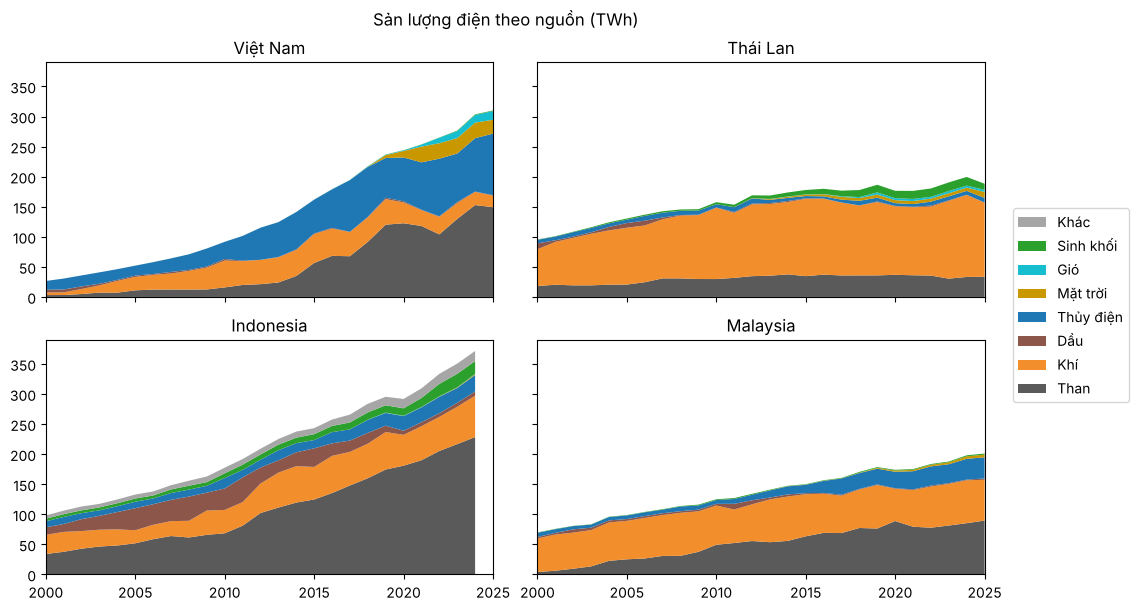

In [29]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
for ax, qg in zip(axs.flat, ["Việt Nam", "Thái Lan", "Indonesia", "Malaysia"]):
    d = dien[dien.quoc_gia == qg].set_index("nam")
    ax.stackplot(d.index, [d[ng] for ng in NGUON],
                 labels=[TEN_NGUON[ng] for ng in NGUON], colors=[MAU_NGUON[ng] for ng in NGUON])
    ax.set_title(qg)
    ax.set_xlim(2000, 2025)
fig.suptitle("Sản lượng điện theo nguồn (TWh)")
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

Cùng thang trục nên thấy ngay (số liệu Indonesia đến năm 2024): Indonesia sản xuất nhiều điện nhất và chủ yếu từ than; Thái Lan chủ yếu từ khí; Việt Nam tăng nhanh nhất và có cơ cấu đa dạng nhất (thủy điện, than, khí, mặt trời, gió).

**Hai đại lượng khác đơn vị** (ví dụ sản lượng TWh và bình quân kWh/người): không vẽ chung một biểu đồ với hai trục tung, mà dùng hai biểu đồ chung trục hoành (Phần 3 sẽ bàn vì sao biểu đồ hai trục tung dễ gây hiểu lầm).

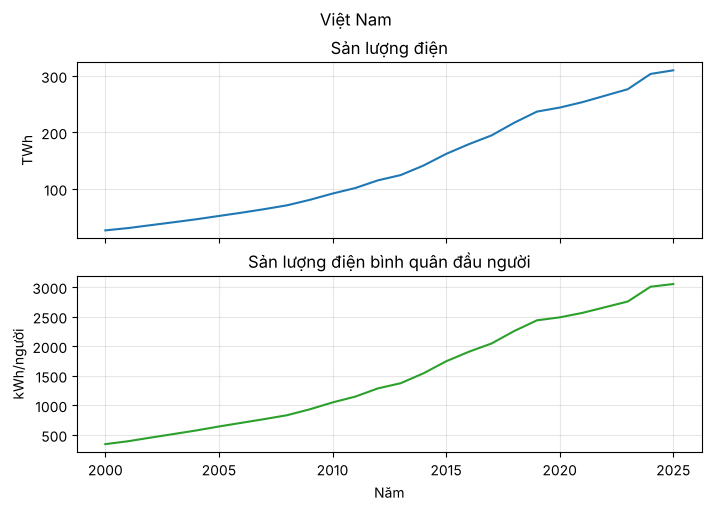

In [30]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True, layout="constrained")
ax1.plot(vn.index, vn.san_luong)
ax1.set_title("Sản lượng điện")
ax1.set_ylabel("TWh")
ax2.plot(vn.index, vn.binh_quan, color="tab:green")
ax2.set_title("Sản lượng điện bình quân đầu người")
ax2.set_ylabel("kWh/người")
ax2.set_xlabel("Năm")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.suptitle("Việt Nam")
plt.show()

## <a name="luu_hinh"/>Lưu hình và đưa vào báo cáo

Lưu hình bằng phương thức [`savefig`](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.savefig.html):

* **PNG** (ảnh điểm) với độ phân giải `dpi` 200 - 300 để chèn vào Word, PowerPoint.
* **SVG**, **PDF** (ảnh vector): phóng to không bị vỡ, phù hợp in ấn.
* `bbox_inches="tight"` cắt bỏ lề thừa.
* Kích thước `figsize` tính bằng inch; nên vẽ đúng kích thước sẽ dùng để chữ không bị quá nhỏ khi chèn vào tài liệu.

In [31]:
import os

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(vn.index, vn.san_luong, marker="o", markersize=3)
ax.set_title("Sản lượng điện của Việt Nam")
ax.set_xlabel("Năm")
ax.set_ylabel("TWh")
ax.grid(alpha=0.3)

fig.savefig("san_luong_dien_vn.png", dpi=200, bbox_inches="tight")
fig.savefig("san_luong_dien_vn.svg", bbox_inches="tight")
plt.close(fig)                        # không hiển thị hình trong notebook

for ten in ["san_luong_dien_vn.png", "san_luong_dien_vn.svg"]:
    print(ten, os.path.getsize(ten) // 1024, "KB")

san_luong_dien_vn.png 55 KB
san_luong_dien_vn.svg 29 KB


Có thể đổi **style** cho mọi biểu đồ (`plt.style.use`) hoặc chỉ tạm thời trong một khối lệnh (`plt.style.context`). Tham khảo: [Style sheets reference](https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html). Style `tableau-colorblind10` dùng bảng màu được thiết kế cho người khiếm khuyết sắc giác (khoảng 8% nam giới).

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


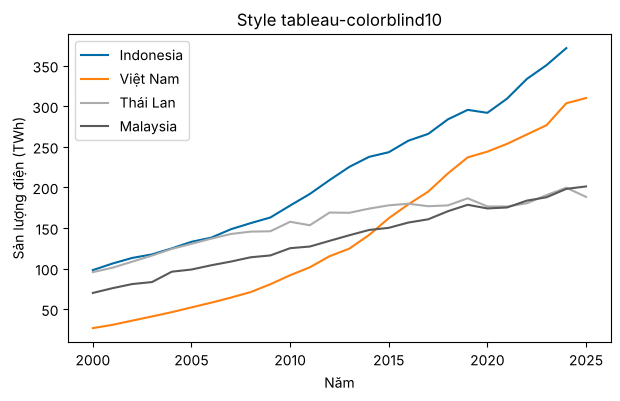

In [32]:
print(plt.style.available)

with plt.style.context("tableau-colorblind10"):
    fig, ax = plt.subplots(figsize=(7, 4))
    for qg in ["Indonesia", "Việt Nam", "Thái Lan", "Malaysia"]:
        d = dien[dien.quoc_gia == qg]
        ax.plot(d.nam, d.san_luong, label=qg)
    ax.set_title("Style tableau-colorblind10")
    ax.set_xlabel("Năm")
    ax.set_ylabel("Sản lượng điện (TWh)")
    ax.legend()
    plt.show()

## <a name="goc_ai"/>Góc AI

Nhắc lại **cấp độ 4 - ra lệnh bằng lời** (Bài Lập trình với AI). Một lệnh vẽ biểu đồ tốt cần có: **bối cảnh** (thư viện, cách viết), **mô tả dữ liệu** (dán kết quả `info()`, `head()` thay vì dán cả dữ liệu), **câu hỏi** cần trả lời, **loại biểu đồ** và **yêu cầu trình bày**.

```text
Tôi dùng Python, pandas và Matplotlib (cách hướng đối tượng fig, ax) trong Jupyter.
DataFrame `dien` có cấu trúc như sau: <dán kết quả dien.info() và dien.head()>
Câu hỏi: cơ cấu nguồn điện của Việt Nam năm 2024 gồm những nguồn nào, mỗi nguồn chiếm bao nhiêu phần trăm?
Hãy vẽ biểu đồ thanh ngang các tỉ lệ (%), sắp xếp giảm dần, tiêu đề và nhãn tiếng Việt, ghi đơn vị.
```

Một câu trả lời điển hình (minh họa):

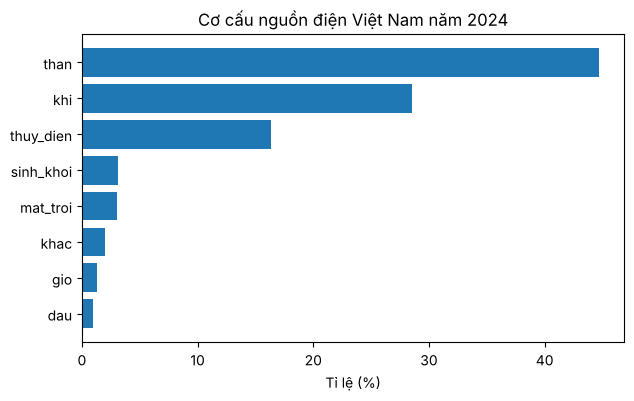

In [33]:
# ===== Code do AI sinh (minh họa) =====
cac_nguon = ["than", "khi", "dau", "thuy_dien", "mat_troi", "gio", "sinh_khoi", "khac"]
d = dien[dien["nam"] == 2024]
ti_le_ai = d[cac_nguon].sum() / d[cac_nguon].sum().sum() * 100
ti_le_ai = ti_le_ai.sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(ti_le_ai.index, ti_le_ai.values)
ax.set_xlabel("Tỉ lệ (%)")
ax.set_title("Cơ cấu nguồn điện Việt Nam năm 2024")
plt.show()

Biểu đồ trông hợp lý và chạy không lỗi. Hãy **in ra bảng số liệu nằm sau biểu đồ** và đối chiếu với điều đã biết.

In [34]:
print(d[["quoc_gia", "nam", "san_luong"]], "\n")
print("Tổng sản lượng dùng để tính tỉ lệ:", round(d[cac_nguon].sum().sum(), 2), "TWh")
print("Sản lượng của Việt Nam năm 2024: ", vn.loc[2024, "san_luong"], "TWh")

        quoc_gia   nam  san_luong
24        Brunei  2024       5.56
49     Campuchia  2024      15.48
75     Indonesia  2024     371.54
100          Lào  2024      52.31
125     Malaysia  2024     198.12
151      Myanmar  2024      21.71
176  Philippines  2024     124.17
202    Singapore  2024      59.61
228     Thái Lan  2024     199.52
254     Việt Nam  2024     303.58 

Tổng sản lượng dùng để tính tỉ lệ: 1351.6 TWh
Sản lượng của Việt Nam năm 2024:  303.58 TWh


Biểu đồ được tính trên **cả 10 nước** (AI quên lọc Việt Nam) nhưng tiêu đề lại ghi "Việt Nam": khí thành khoảng 29% thay vì 7%, thủy điện chỉ còn khoảng 16% thay vì 29%, than khoảng 45% thay vì 50%. Đây là **lỗi lặng lẽ**: chạy được, trông hợp lý, nhưng sai.

Sửa lại và thêm các lệnh `assert` để lần sau lỗi tự lộ ra:

In [35]:
d = dien[(dien["nam"] == 2024) & (dien["quoc_gia"] == "Việt Nam")]
assert len(d) == 1                                   # đúng một dòng: Việt Nam năm 2024
ti_le_dung = (d[cac_nguon].sum() / d[cac_nguon].sum().sum() * 100).sort_values()
assert abs(ti_le_dung.sum() - 100) < 1e-9            # tổng các tỉ lệ bằng 100%
ti_le_dung.rename(TEN_NGUON).round(1)

Khác          0.0
Dầu           0.2
Sinh khối     0.3
Gió           4.2
Khí           7.2
Mặt trời      8.5
Thủy điện    29.2
Than         50.3
dtype: float64

**Thói quen cần có**: với mỗi biểu đồ do AI vẽ, in ra (hoặc kiểm tra bằng `assert`) bảng số liệu nằm sau biểu đồ: đúng nhóm, đúng số dòng, các tổng có khớp không?

**Bài tập** *(sinh viên tự rèn luyện, có thể được điểm cộng trong giờ học trực tuyến)*.

1. Hoàn chỉnh biểu đồ cơ cấu ở trên: dùng tên và màu trong `TEN_NGUON`, `MAU_NGUON`, bỏ các nguồn 0%, ghi giá trị ở cuối mỗi thanh.
1. Nhờ AI chuyển một ô code viết theo cách dựa trên trạng thái (`plt.`) ở các bài trước sang cách hướng đối tượng. Kiểm tra hai hình có giống nhau không.

In [36]:
# TODO: